In [ ]:
import numpy as np
!pip install numdifftools
import numdifftools as nd
import matplotlib.pyplot as plt

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.2/100.2 kB 1.1 MB/s eta 0:00:00


defining the objective functions and their gradients

In [189]:
#defining the first function
def rosen(x):
    return (1-x[0])**2 +100*(x[1]-x[0]**2)**2

def sec_func(x):     #x: 4d
  return (x[0] - 10*x[1])**2 + 5*(x[2] -x[3])**2 + (x[1] - 2*x[2])**4 + 10*(x[0] - x[3])**4

###############################################################################

##**Q1 - FOR FUNC (A)**

In [97]:
def line_search(x, pk, c1=1e-3, c2=0.9,
                 alpha=1.0, alpha_max=100.0, max_iters=100,
                 verbose=False):
    #Compute the function and the gradient at alpha = 0
    func_count_a = 0
    grad_count_a = 0
    fk = rosen(x)
    func_count_a +=1
    gk = nd.Gradient(rosen)(x)
    grad_count_a +=1
    # Compute the dot product of the gradient with the search
    # direction to evaluate the derivative of the merit function
    proj_gk = np.dot(gk, pk)

    # Store the old value of the objective
    fj_old = fk
    proj_gj_old = proj_gk
    alpha_old = 0.0

    for j in range(max_iters):
        # Evaluate the merit function
        fj = rosen(x + alpha*pk)
        func_count_a +=1
        # Evaluate the gradient at the new point
        gj = nd.Gradient(rosen)(x + alpha*pk)
        proj_gj = np.dot(gj, pk)
        grad_count_a +=1
        # Check if either the sufficient decrease condition is
        # violated or the objective increased
        if (fj > fk + c1*alpha*proj_gk or
            (j > 0 and fj > fj_old)):
            if verbose:
                print('Sufficient decrease conditions violated: interval found')
            # Zoom and return
            alpha_j, func_count_z, grad_count_z = zoom(fj_old, proj_gj_old, alpha_old,
                        fj, proj_gj, alpha,
                        x, fk, gk, pk, c1=c1, c2=c2, verbose=verbose)
            print("testA", func_count_z, grad_count_z )
            return alpha_j, func_count_z+func_count_a, grad_count_z+grad_count_a

        # Check if the strong Wolfe conditions are satisfied
        if np.fabs(proj_gj) <= c2*np.fabs(proj_gk):
            if verbose:
                print('Strong Wolfe alpha found directly')
            rosen(x + alpha*pk)
            func_count_a +=1
            return alpha, func_count_z+func_count_a, grad_count_z+grad_count_a

        # If the line search is vioalted
        if proj_gj >= 0.0:
            if verbose:
                print('Slope condition violated; interval found')
            alpha_j, func_count_z, grad_count_z = zoom(fj, proj_gj, alpha,
                        fj_old, proj_gj_old, alpha_old,
                        x, fk, gk, pk, c1=c1, c2=c2, verbose=verbose)
            print("TestB2", func_count_z, grad_count_z )
            return alpha_j, func_count_z+func_count_a, grad_count_z+grad_count_a

        # Record the old values of alpha and fj
        fj_old = fj
        proj_gj_old = proj_gj
        alpha_old = alpha

        # Pick a new value for alpha
        alpha = min(2.0*alpha, alpha_max)

        if alpha >= alpha_max:
            if verbose:
                print('Line search failed here')
            return None

    if verbose:
        print('Line search unsuccessful')
    return alpha_j, func_count_z+func_count_a, grad_count_z+grad_count_a

def zoom(f_low, proj_low, alpha_low,
         f_high, proj_high, alpha_high,
         x, fk, gk, pk, c1=1e-3, c2=0.9, max_iters=100, verbose=False):

    func_count_z = 0
    grad_count_z = 0
    proj_gk = np.dot(pk, gk)

    for j in range(max_iters):
        # Pick an alpha value by bisecting the interval
        alpha_j = 0.5*(alpha_high + alpha_low)

        # Evaluate the merit function
        fj = rosen(x + alpha_j*pk)
        func_count_z +=1
        # Check if the sufficient decrease condition is violated
        if fj > fk + c1*alpha_j or fj >= f_low:
            if verbose:
                print('Zoom: Sufficient decrease conditions violated')
            alpha_high = alpha_j
            f_high = fj

            # We need the derivative here for proj_high
            gj = nd.Gradient(rosen)(x + alpha_j*pk)
            proj_high = np.dot(gj, pk)
            grad_count_z +=1
        else:
            # Evaluate the gradient of the function and the
            # derivative of the merit function
            gj = nd.Gradient(rosen)(x + alpha_j*pk)
            proj_gj = np.dot(gj, pk)
            grad_count_z +=1
            # Return alpha, the strong Wolfe conditions are
            # satisfied
            if np.fabs(proj_gj) <= c2*np.fabs(proj_gk):
                if verbose:
                    print('Zoom: Wolfe conditions satisfied')
                rosen(x + alpha_j*pk)
                func_count_z +=1
                return alpha_j,func_count_z, grad_count_z
            elif verbose:
                 print('Zoom: Curvature condition violated')

            # Make sure that we have the intervals right
            if proj_gj*(alpha_high - alpha_low) >= 0.0:
                # Swap alpha high/alpha low
                alpha_high = alpha_low
                proj_high = proj_low
                f_high = f_low

            # Swap alpha low/alpha j
            alpha_low = alpha_j
            proj_low = proj_gj
            f_low = fj

    return alpha_j,func_count_z, grad_count_z

the main function


In [153]:
x0 = [1.0, 2.0]
n_iter=20
# alpha = 0.01
func_count_a = 0
grad_count_a = 0
f = []
x = []
grad = []
x_old = x0
f_old = rosen(x0)
func_count_a += 1
d = -nd.Gradient(rosen)(x0)
grad_count_a += 1
alpha, func_count_dummy, grad_count_dummy = line_search(x_old, d, c2=0.1)
func_count_a += func_count_dummy
grad_count_a += grad_count_dummy
x_new = x_old + alpha*d
f_new = rosen(x_new)
func_count_a += 1
print("Count of Func Calculation", func_count_a)
print("Count of Grad Calculation", grad_count_a)

f.append(f_old)
x.append(x_old)

for _ in range(n_iter):
  grad.append(np.linalg.norm(d))
  f_new = rosen(x_new)
  func_count_a +=1
  d = -nd.Gradient(rosen)(x_new)
  grad_count_a +=1
  x_old = x_new
  # alpha = line_search_func1(x_old, alpha, d, c1=0.001, c2=0.9, max_iterations=100)
  alpha, func_count_dummy, grad_count_dummy = line_search(x_old, d, c2=0.1)
  func_count_a += func_count_dummy
  grad_count_a += grad_count_dummy
  x_new = x_old + alpha*d
  f.append(f_new)
  x.append(x_new)
  print("num of iteration:", _)
  print("optimal step value:", alpha)
  print("function value of step:", f[_])
  print("optimal x at iteration:", x[_])
  print("Count of Func Calculation", func_count_a)
  print("Count of Grad Calculation", grad_count_a)



testA 14 13
Count of Func Calculation 18
Count of Grad Calculation 16
testA 14 13
num of iteration: 0
optimal step value: 0.0006103515625
function value of step: 100.0
optimal x at iteration: [1.0, 2.0]
Count of Func Calculation 35
Count of Grad Calculation 32
testA 10 9
num of iteration: 1
optimal step value: 0.005859375
function value of step: 0.19909488182747737
optimal x at iteration: [1.35077573 1.82560026]
Count of Func Calculation 48
Count of Grad Calculation 44
testA 13 12
num of iteration: 2
optimal step value: 0.000732421875
function value of step: 0.12314465173484743
optimal x at iteration: [1.34984737 1.8244223 ]
Count of Func Calculation 64
Count of Grad Calculation 59
testA 12 11
num of iteration: 3
optimal step value: 0.00244140625
function value of step: 0.12293811274154276
optimal x at iteration: [1.35025806 1.82408035]
Count of Func Calculation 79
Count of Grad Calculation 73
testA 13 12
num of iteration: 4
optimal step value: 0.000732421875
function value of step: 0.

In [154]:
x

[[1.0, 2.0],
 array([1.35077573, 1.82560026]),
 array([1.34984737, 1.8244223 ]),
 array([1.35025806, 1.82408035]),
 array([1.34971284, 1.82364894]),
 array([1.34996144, 1.82336708]),
 array([1.34919024, 1.82251349]),
 array([1.349548  , 1.82219134]),
 array([1.34894146, 1.82165724]),
 array([1.34922632, 1.8213622 ]),
 array([1.34850189, 1.82061958]),
 array([1.34884562, 1.82030285]),
 array([1.34825321, 1.81976476]),
 array([1.34852439, 1.81947501]),
 array([1.34781795, 1.81872737]),
 array([1.34814326, 1.81841768]),
 array([1.34756856, 1.81787427]),
 array([1.34782266, 1.81759108]),
 array([1.34705228, 1.8167428 ]),
 array([1.34740934, 1.81642157]),
 array([1.34681005, 1.81588858])]

##Plotting for part a of q1

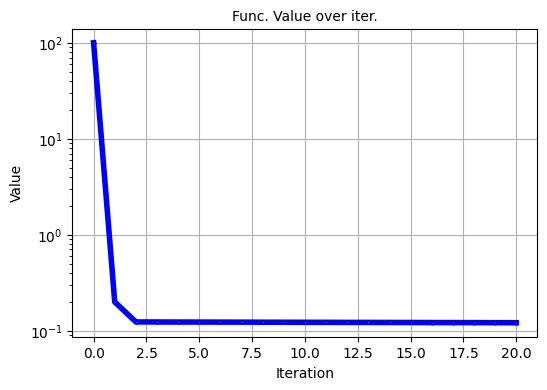

In [ ]:
fig = plt.figure()
fig.set_figheight(4)
fig.set_figwidth(6)
ax = fig.add_subplot(111)

ax.plot(list(range(0,len(f))), f, color='b', linestyle='solid', linewidth = 4,
            marker='o', markerfacecolor='tab:blue', markersize=2)
ax.set_yscale('log')
ax.set_title('Func. Value over iter.', fontsize=10)
ax.set_ylabel('Value', fontsize=10)
ax.set_xlabel('Iteration', fontsize=10)
# ax.legend(fontsize=30)
ax.grid()
plt.show()

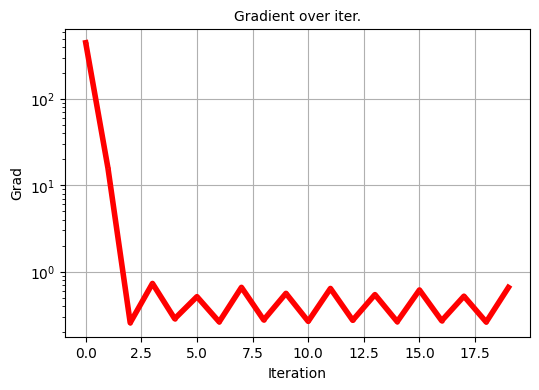

In [ ]:
fig = plt.figure()
fig.set_figheight(4)
fig.set_figwidth(6)
ax = fig.add_subplot(111)

ax.plot(list(range(0,len(grad))), grad, color='r', linestyle='solid', linewidth = 4,
            marker='o', markerfacecolor='tab:red', markersize=2)
ax.set_yscale('log')
ax.set_title('Gradient over iter.', fontsize=10)
ax.set_ylabel('Grad', fontsize=10)
ax.set_xlabel('Iteration', fontsize=10)
# ax.legend(fontsize=30)
ax.grid()
plt.show()

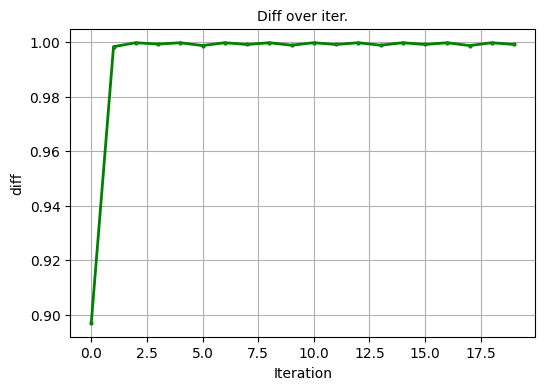

In [ ]:
fig = plt.figure()
fig.set_figheight(4)
fig.set_figwidth(6)
ax = fig.add_subplot(111)
plot_x=np.array(x)

diff = plot_x-[1,1]

plot_diff_list =[]
for i in range(1, len(diff)):
  plot_diff = np.linalg.norm(diff[i])/np.linalg.norm(diff[i-1])
  plot_diff_list.append(plot_diff)


ax.plot(list(range(0,len(plot_diff_list))), plot_diff_list, color='g', linestyle='solid', linewidth = 2,
            marker='o', markerfacecolor='tab:green', markersize=2)
ax.set_title('Diff over iter.', fontsize=10)
ax.set_ylabel('diff', fontsize=10)
ax.set_xlabel('Iteration', fontsize=10)
# ax.legend(fontsize=30)
ax.grid()
plt.show()

##**Q1 - FOR FUNCTION(B)**

In [96]:
def line_search_2(x, pk, c1=1e-3, c2=0.9,
                 alpha=1.0, alpha_max=100.0, max_iters=100,
                 verbose=False):
    #Compute the function and the gradient at alpha = 0
    func_count_b = 0
    grad_count_b = 0
    fk = sec_func(x)
    gk = nd.Gradient(sec_func)(x)
    func_count_b +=1
    grad_count_b +=1
    # Compute the dot product of the gradient with the search
    # direction to evaluate the derivative of the merit function
    proj_gk = np.dot(gk, pk)

    # Store the old value of the objective
    fj_old = fk
    proj_gj_old = proj_gk
    alpha_old = 0.0

    for j in range(max_iters):
        # Evaluate the merit function
        fj = sec_func(x + alpha*pk)
        func_count_b +=1
        # Evaluate the gradient at the new point
        gj = nd.Gradient(sec_func)(x + alpha*pk)
        proj_gj = np.dot(gj, pk)
        grad_count_b +=1
        # Check if either the sufficient decrease condition is
        # violated or the objective increased
        if (fj > fk + c1*alpha*proj_gk or
            (j > 0 and fj > fj_old)):
            if verbose:
                print('Sufficient decrease conditions violated: interval found')
            # Zoom and return
            alpha_j, func_count_k, grad_count_k = zoom(fj_old, proj_gj_old, alpha_old,
                        fj, proj_gj, alpha,
                        x, fk, gk, pk, c1=c1, c2=c2, verbose=verbose)
            print("testA2", func_count_k, grad_count_k )
            return alpha_j, func_count_k + func_count_b , grad_count_k + grad_count_b

        # Check if the strong Wolfe conditions are satisfied
        if np.fabs(proj_gj) <= c2*np.fabs(proj_gk):
            if verbose:
                print('Strong Wolfe alpha found directly')
            sec_func(x + alpha*pk)
            func_count_b +=1
            return alpha, func_count_k + func_count_b , grad_count_k + grad_count_b

        # If the line search is vioalted
        if proj_gj >= 0.0:
            if verbose:
                print('Slope condition violated; interval found')
            alpha_j, func_count_k, grad_count_k = zoom(fj, proj_gj, alpha,
                        fj_old, proj_gj_old, alpha_old,
                        x, fk, gk, pk, c1=c1, c2=c2, verbose=verbose)
            print("TestB2", func_count_k, grad_count_k)
            return alpha_j, func_count_k + func_count_b, grad_count_k + grad_count_b

        # Record the old values of alpha and fj
        fj_old = fj
        proj_gj_old = proj_gj
        alpha_old = alpha

        # Pick a new value for alpha
        alpha = min(2.0*alpha, alpha_max)

        if alpha >= alpha_max:
            if verbose:
                print('Line search failed here')
            return None

    if verbose:
        print('Line search unsuccessful')
    return alpha_j, func_count_k + func_count_b, grad_count_k + grad_count_b

def zoom(f_low, proj_low, alpha_low,
         f_high, proj_high, alpha_high,
         x, fk, gk, pk, c1=1e-3, c2=0.9, max_iters=100, verbose=False):

    func_count_k = 0
    grad_count_k = 0
    proj_gk = np.dot(pk, gk)

    for j in range(max_iters):
        # Pick an alpha value by bisecting the interval
        alpha_j = 0.5*(alpha_high + alpha_low)

        # Evaluate the merit function
        fj = sec_func(x + alpha_j*pk)
        func_count_k +=1
        # Check if the sufficient decrease condition is violated
        if fj > fk + c1*alpha_j or fj >= f_low:
            if verbose:
                print('Zoom: Sufficient decrease conditions violated')
            alpha_high = alpha_j
            f_high = fj

            # We need the derivative here for proj_high
            gj = nd.Gradient(sec_func)(x + alpha_j*pk)
            grad_count_k +=1
            proj_high = np.dot(gj, pk)
        else:
            # Evaluate the gradient of the function and the
            # derivative of the merit function
            gj = nd.Gradient(sec_func)(x + alpha_j*pk)
            grad_count_k +=1
            proj_gj = np.dot(gj, pk)

            # Return alpha, the strong Wolfe conditions are
            # satisfied
            if np.fabs(proj_gj) <= c2*np.fabs(proj_gk):
                if verbose:
                    print('Zoom: Wolfe conditions satisfied')
                sec_func(x + alpha_j*pk)
                func_count_k +=1
                return alpha_j
            elif verbose:
                 print('Zoom: Curvature condition violated')

            # Make sure that we have the intervals right
            if proj_gj*(alpha_high - alpha_low) >= 0.0:
                # Swap alpha high/alpha low
                alpha_high = alpha_low
                proj_high = proj_low
                f_high = f_low

            # Swap alpha low/alpha j
            alpha_low = alpha_j
            proj_low = proj_gj
            f_low = fj

    return alpha_j, func_count_k , grad_count_k

In [101]:
x0 = [1.0, 2.0, 2.0, 2.0]
n_iter=20
# alpha = 0.01
func_count_b = 0
grad_count_b = 0
f = []
x = []
grad = []
x_old = x0
f_old = sec_func(x0)
func_count_b += 1
d = -nd.Gradient(sec_func)(x0)
grad_count_b += 1
alpha, func_count_dummy, grad_count_dummy = line_search_2(x_old, d, c2=0.1)
func_count_b += func_count_dummy
grad_count_b += grad_count_dummy
x_new = x_old + alpha*d
f_new = sec_func(x_new)
func_count_b += 1
print("Count of Func Calcultion:", func_count_b)
print("Count of Grad Calcultion:", grad_count_b)

f.append(f_old)
x.append(x_old)

for _ in range(n_iter):
  grad.append(np.linalg.norm(d))
  f_new = sec_func(x_new)
  func_count_b += 1
  d = -nd.Gradient(sec_func)(x_new)
  grad_count_b += 1
  x_old = x_new
  # alpha = line_search_func1(x_old, alpha, d, c1=0.001, c2=0.9, max_iterations=100)
  alpha, func_count_dummy, grad_count_dummy = line_search(x_old, d, c2=0.1)
  func_count_b += func_count_dummy
  grad_count_b += grad_count_dummy
  x_new = x_old + alpha*d
  f.append(f_new)
  x.append(x_new)
  print("num of iteration:", _)
  print("optimal step value:", alpha)
  print("function value of step:", f[_])
  print("optimal x at iteration:", x[_])
  print("Count of Func Calcultion:", func_count_b)
  print("Count of Grad Calcultion:", grad_count_b)

testA2 10 9
Count of Func Calcultion: 14
Count of Grad Calcultion: 12
testA 100 100
num of iteration: 0
optimal step value: 7.888609052210118e-31
function value of step: 387.0
optimal x at iteration: [1.0, 2.0, 2.0, 2.0]
Count of Func Calcultion: 117
Count of Grad Calcultion: 115
testA 100 100
num of iteration: 1
optimal step value: 7.888609052210118e-31
function value of step: 183.5889783189633
optimal x at iteration: [1.15234375 1.3203125  1.875      1.921875  ]
Count of Func Calcultion: 220
Count of Grad Calcultion: 218
testA 100 100
num of iteration: 2
optimal step value: 7.888609052210118e-31
function value of step: 183.5889783189633
optimal x at iteration: [1.15234375 1.3203125  1.875      1.921875  ]
Count of Func Calcultion: 323
Count of Grad Calcultion: 321
testA 100 100
num of iteration: 3
optimal step value: 7.888609052210118e-31
function value of step: 183.5889783189633
optimal x at iteration: [1.15234375 1.3203125  1.875      1.921875  ]
Count of Func Calcultion: 426
Count

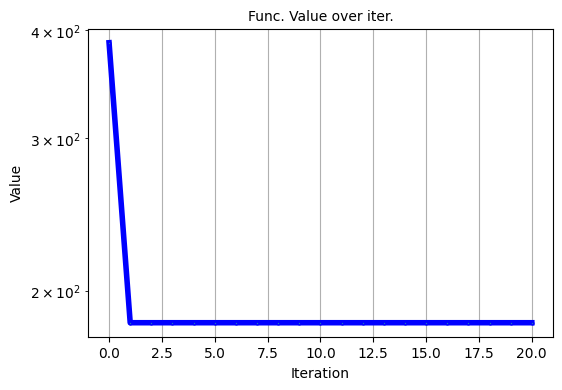

In [102]:
fig = plt.figure()
fig.set_figheight(4)
fig.set_figwidth(6)
ax = fig.add_subplot(111)

ax.plot(list(range(0,len(f))), f, color='b', linestyle='solid', linewidth = 4,
            marker='o', markerfacecolor='tab:blue', markersize=2)
ax.set_yscale('log')
ax.set_title('Func. Value over iter.', fontsize=10)
ax.set_ylabel('Value', fontsize=10)
ax.set_xlabel('Iteration', fontsize=10)
# ax.legend(fontsize=30)
ax.grid()
plt.show()

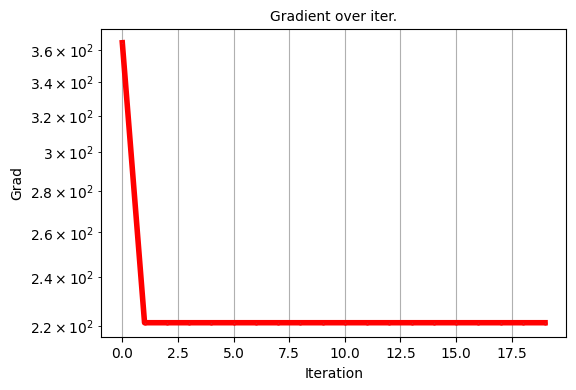

In [103]:
fig = plt.figure()
fig.set_figheight(4)
fig.set_figwidth(6)
ax = fig.add_subplot(111)

ax.plot(list(range(0,len(grad))), grad, color='r', linestyle='solid', linewidth = 4,
            marker='o', markerfacecolor='tab:red', markersize=2)
ax.set_yscale('log')
ax.set_title('Gradient over iter.', fontsize=10)
ax.set_ylabel('Grad', fontsize=10)
ax.set_xlabel('Iteration', fontsize=10)
# ax.legend(fontsize=30)
ax.grid()
plt.show()

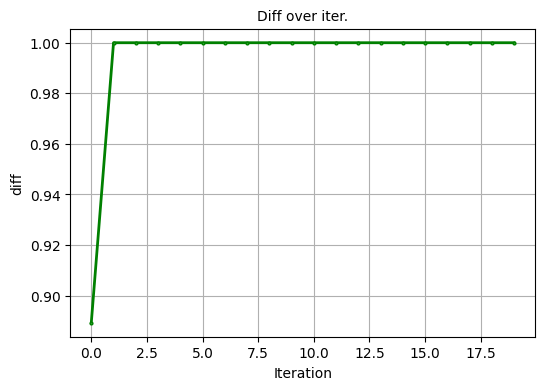

In [104]:
fig = plt.figure()
fig.set_figheight(4)
fig.set_figwidth(6)
ax = fig.add_subplot(111)
plot_x=np.array(x)

diff = plot_x-[0,0,0,0]

plot_diff_list =[]
for i in range(1, len(diff)):
  plot_diff = np.linalg.norm(diff[i])/np.linalg.norm(diff[i-1])
  plot_diff_list.append(plot_diff)


ax.plot(list(range(0,len(plot_diff_list))), plot_diff_list, color='g', linestyle='solid', linewidth = 2,
            marker='o', markerfacecolor='tab:green', markersize=2)
ax.set_title('Diff over iter.', fontsize=10)
ax.set_ylabel('diff', fontsize=10)
ax.set_xlabel('Iteration', fontsize=10)
# ax.legend(fontsize=30)
ax.grid()
plt.show()

In [ ]:
############
##  BFGS  ##
############

def bfgs(x0, func1_grad, max_iter=100, tol=0.0001):
    n = len(x0)
    H = np.eye(n)
    x = x0

    for _ in range(max_iter):
        grad = func1_grad(x)
        d = -np.dot(H, grad)

        alpha = line_search(x, d, c1=0.001, c2=0.9, max_iterations=100)

        x_new = x + alpha * d
        grad_new = func1_grad(x_new)
        s = x_new - x
        y = grad_new - grad

        rho = 1 / np.dot(y, s)

        H = (np.eye(n) - rho * np.outer(s, y)) @ H @ (np.eye(n) - rho * np.outer(y, s)) + rho * np.outer(s, s)

        if np.linalg.norm(x_new - x) < tol:
            break

        x = x_new

    return

##**BFGS** for function (a)

In [119]:
x = [1, 2]
I = np.eye(2)
hessian = I
inverse_hessian = np.linalg.inv(hessian)
gradient = -nd.Gradient(rosen)(x)
search_direction = -np.dot(inverse_hessian, gradient)


In [156]:
def BFGS(x, hessian, line_search):
    max_iterations = 1000
    tolerance = 1e-3
    grad_count_c = 0
    #func_count_c = 0
    # Initialization
    n = len(x)
    k = 0
    I = np.eye(n)
    inverse_hessian = np.linalg.inv(hessian)
    gradient = -nd.Gradient(rosen)(x)
    grad_count_c += 1

    while k < max_iterations and np.linalg.norm(gradient) > tolerance:
        grad_count_e = 0
        #func_count_e = 0
        grad.append(np.linalg.norm(gradient))
        # Compute search direction
        search_direction = np.dot(inverse_hessian, gradient)
        # Perform line search to find optimal step size
        step_size, func_count_dummy, grad_count_dummy = line_search(x, search_direction, c2=0.1)
        #func_count_e += func_count_dummy
        grad_count_e += grad_count_dummy
        # Update x and compute new gradient
        x_new = x + step_size * search_direction
        #f_new = rosen(x_new)
        #f.append(f_new)
        #func_count_e += 1
        gradient_new = -nd.Gradient(rosen)(x_new)
        grad_count_e += 1

        # Compute difference in gradients and x values
        gradient_diff = gradient_new - gradient
        x_diff = x_new - x

        # Update inverse Hessian approximation
        factor1 = np.dot(gradient_diff, x_diff.T)
        factor2 = np.dot(np.dot(inverse_hessian, gradient_diff), inverse_hessian.T)
        inverse_hessian += (factor1 + np.dot(np.dot(x_diff, inverse_hessian), factor2)) / np.dot(x_diff.T, factor1)

        # Update variables for next iteration
        x = x_new
        gradient = gradient_new
        k += 1

        print("num of iteration:", k)
        print("optimal step value:", step_size)
        #print("function value of step:", f)
        print("optimal x at iteration:", x)
        #print("Count of Func Calculation", func_count_e)
        print("Count of Grad Calculation", grad_count_e + grad_count_c)
        x_f.append(x)
    return x, step_size

In [157]:
I = np.eye(2)
hessian = I
x0 = [1.0, 2.0]
n_iter=20
step_size = 1.0
# alpha = 0.01
#func_count_c = 0
grad_count_c = 0
#f = []
x_f = []
grad = []
x_old = x0
#f_old = rosen(x0)
#func_count_c += 1
d = -nd.Gradient(rosen)(x0)
grad_count_c += 1
alpha, func_count_aa, func_count_bb = line_search(x_old, d, c2=0.1)
#func_count_c += func_count_dummy
x_new = x_old + alpha*d
#f_new = rosen(x_new)
#func_count_c += 1
#print("Count of Func Calculation", func_count_c)
#print("Count of Grad Calculation", grad_count_c)

#f.append(f_old)
x_f.append(x_old)

x, step_size = BFGS(x_old, hessian, line_search)
#x.append(x)
#for _ in range(n_iter):

#  f_new = rosen(x_new)
#  func_count_a +=1
#  d = -nd.Gradient(rosen)(x_new)
#  grad_count_a +=1
#  x_old = x_new
  # alpha = line_search_func1(x_old, alpha, d, c1=0.001, c2=0.9, max_iterations=100)
#  alpha, func_count_dummy, grad_count_dummy = line_search(x_old, d, c2=0.1)
#  func_count_a += func_count_dummy
#  grad_count_a += grad_count_dummy
#  x_new = x_old + alpha*d
#  f.append(f_new)
#  x.append(x_new)
#  print("num of iteration:", _)
#  print("optimal step value:", alpha)
#  print("function value of step:", f[_])
#  print("optimal x at iteration:", x[_])
#  print("Count of Func Calculation", func_count_a)
#  print("Count of Grad Calculation", grad_count_a)


testA 14 13
testA 14 13
num of iteration: 1
optimal step value: 0.0008544921875
optimal x at iteration: [1.34179688 1.82910156]
Count of Grad Calculation 17
testA 16 15
num of iteration: 2
optimal step value: 9.1552734375e-05
optimal x at iteration: [1.35717087 1.84260353]
Count of Grad Calculation 19
testA 27 26
num of iteration: 3
optimal step value: 4.470348358154297e-08
optimal x at iteration: [1.35635872 1.84179139]
Count of Grad Calculation 30
testA 100 100
num of iteration: 4
optimal step value: 7.888609052210118e-31
optimal x at iteration: [1.35635872 1.84179139]
Count of Grad Calculation 104
testA 100 100
num of iteration: 5
optimal step value: 7.888609052210118e-31
optimal x at iteration: [2.22633996e+36 2.22633996e+36]
Count of Grad Calculation 104


In [158]:
x_f

[[1.0, 2.0],
 array([1.34179688, 1.82910156]),
 array([1.35717087, 1.84260353]),
 array([1.35635872, 1.84179139]),
 array([1.35635872, 1.84179139]),
 array([2.22633996e+36, 2.22633996e+36])]

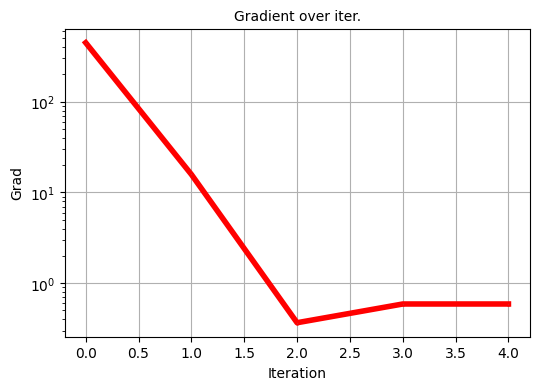

In [159]:
fig = plt.figure()
fig.set_figheight(4)
fig.set_figwidth(6)
ax = fig.add_subplot(111)

ax.plot(list(range(0,len(grad))), grad, color='r', linestyle='solid', linewidth = 4,
            marker='o', markerfacecolor='tab:red', markersize=2)
ax.set_yscale('log')
ax.set_title('Gradient over iter.', fontsize=10)
ax.set_ylabel('Grad', fontsize=10)
ax.set_xlabel('Iteration', fontsize=10)
# ax.legend(fontsize=30)

ax.grid()
plt.show()

In [ ]:
'''
fig = plt.figure()
fig.set_figheight(4)
fig.set_figwidth(6)
ax = fig.add_subplot(111)
x_vals = []
y_vals = []
for i in range(0,len(x_f)):
  x_vals = x_f[i][0]
  y_vals = x_f[i][1]

ax.plot(x_vals, y_vals, color='r', linestyle='solid', linewidth = 4,
            marker='o', markerfacecolor='tab:red', markersize=2)

#ax.set_yscale('log')
ax.set_title('x* over iter.', fontsize=10)
ax.set_ylabel('x*', fontsize=10)
ax.set_xlabel('Iteration', fontsize=10)
# ax.legend(fontsize=30)

plt.ylim(-2,1.5)
ax.grid()
plt.show()

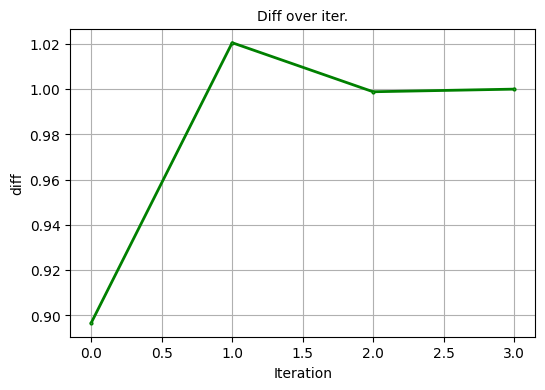

In [188]:
fig = plt.figure()
fig.set_figheight(4)
fig.set_figwidth(6)
ax = fig.add_subplot(111)
plot_x=np.array(x_f[0:5])
diff = plot_x-[1,1]

plot_diff_list =[]
for i in range(1, len(diff)):
  plot_diff = np.linalg.norm(diff[i])/np.linalg.norm(diff[i-1])
  plot_diff_list.append(plot_diff)


ax.plot(list(range(0,len(plot_diff_list))), plot_diff_list, color='g', linestyle='solid', linewidth = 2,
            marker='o', markerfacecolor='tab:green', markersize=2)
ax.set_title('Diff over iter.', fontsize=10)
ax.set_ylabel('diff', fontsize=10)
ax.set_xlabel('Iteration', fontsize=10)
# ax.legend(fontsize=30)
ax.grid()
plt.show()

##**BFGS** for function (b)

In [194]:
def BFGS(x, hessian, line_search):
    max_iterations = 1000
    tolerance = 1e-20
    grad_count_c = 0
    #func_count_c = 0
    # Initialization
    n = len(x)
    k = 0
    I = np.eye(n)
    inverse_hessian = np.linalg.inv(hessian)
    gradient = -nd.Gradient(sec_func)(x)
    grad_count_c += 1

    while k < max_iterations and np.linalg.norm(gradient) > tolerance:
        grad_count_e = 0
        #func_count_e = 0
        grad.append(np.linalg.norm(gradient))
        # Compute search direction
        search_direction = np.dot(inverse_hessian, gradient)
        # Perform line search to find optimal step size
        step_size, func_count_dummy, grad_count_dummy = line_search_2(x, search_direction, c2=0.1)
        #func_count_e += func_count_dummy
        grad_count_e += grad_count_dummy
        # Update x and compute new gradient
        x_new = x + step_size * search_direction
        #f_new = rosen(x_new)
        #f.append(f_new)
        #func_count_e += 1
        gradient_new = -nd.Gradient(sec_func)(x_new)
        grad_count_e += 1

        # Compute difference in gradients and x values
        gradient_diff = gradient_new - gradient
        x_diff = x_new - x

        # Update inverse Hessian approximation
        factor1 = np.dot(gradient_diff, x_diff.T)
        factor2 = np.dot(np.dot(inverse_hessian, gradient_diff), inverse_hessian.T)
        inverse_hessian += (factor1 + np.dot(np.dot(x_diff, inverse_hessian), factor2)) / np.dot(x_diff.T, factor1)

        # Update variables for next iteration
        x = x_new
        gradient = gradient_new
        k += 1

        print("num of iteration:", k)
        print("optimal step value:", step_size)
        #print("function value of step:", f)
        print("optimal x at iteration:", x)
        #print("Count of Func Calculation", func_count_e)
        print("Count of Grad Calculation", grad_count_e + grad_count_c)
        x_f.append(x)
    return x, step_size

In [195]:
I = np.eye(4)
hessian = I
x0 = [1.0, 2.0, 2.0, 2.0]
n_iter=20
step_size = 1.0
# alpha = 0.01
#func_count_c = 0
grad_count_c = 0
#f = []
x_f = []
grad = []
x_old = x0
#f_old = rosen(x0)
#func_count_c += 1
d = -nd.Gradient(sec_func)(x0)
grad_count_c += 1
alpha, func_count_aa, func_count_bb = line_search_2(x_old, d, c2=0.1)
#func_count_c += func_count_dummy
x_new = x_old + alpha*d
#f_new = rosen(x_new)
#func_count_c += 1
#print("Count of Func Calculation", func_count_c)
#print("Count of Grad Calculation", grad_count_c)

#f.append(f_old)
x_f.append(x_old)

x, step_size = BFGS(x_old, hessian, line_search)
#x.append(x)



testA2 10 9
testA2 10 9
num of iteration: 1
optimal step value: 0.001953125
optimal x at iteration: [1.15234375 1.3203125  1.875      1.921875  ]
Count of Grad Calculation 13
testA2 17 16
num of iteration: 2
optimal step value: 1.52587890625e-05
optimal x at iteration: [1.20491792 1.36943862 1.92518453 1.97351799]
Count of Grad Calculation 20
testA2 36 35
num of iteration: 3
optimal step value: 2.9103830456733704e-11
optimal x at iteration: [1.21255975 1.37708044 1.93282635 1.98115981]
Count of Grad Calculation 39
testA2 90 89
num of iteration: 4
optimal step value: 1.6155871338926322e-27
optimal x at iteration: [1.21537049 1.37989118 1.93563709 1.98397055]
Count of Grad Calculation 93
testA2 100 100
num of iteration: 5
optimal step value: 7.888609052210118e-31
optimal x at iteration: [1.14542679e+42 1.14542679e+42 1.14542679e+42 1.14542679e+42]
Count of Grad Calculation 104


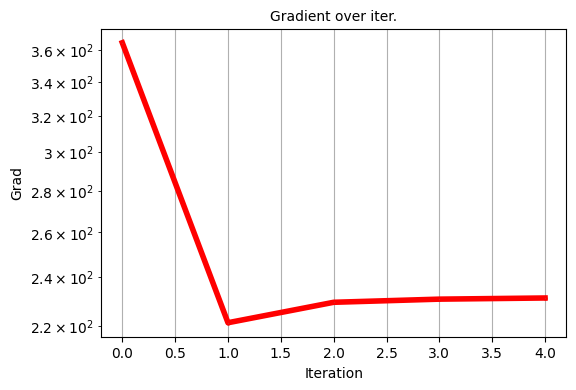

In [196]:
fig = plt.figure()
fig.set_figheight(4)
fig.set_figwidth(6)
ax = fig.add_subplot(111)

ax.plot(list(range(0,len(grad))), grad, color='r', linestyle='solid', linewidth = 4,
            marker='o', markerfacecolor='tab:red', markersize=2)
ax.set_yscale('log')
ax.set_title('Gradient over iter.', fontsize=10)
ax.set_ylabel('Grad', fontsize=10)
ax.set_xlabel('Iteration', fontsize=10)
# ax.legend(fontsize=30)

ax.grid()
plt.show()

In [197]:
x_f

[[1.0, 2.0, 2.0, 2.0],
 array([1.15234375, 1.3203125 , 1.875     , 1.921875  ]),
 array([1.20491792, 1.36943862, 1.92518453, 1.97351799]),
 array([1.21255975, 1.37708044, 1.93282635, 1.98115981]),
 array([1.21537049, 1.37989118, 1.93563709, 1.98397055]),
 array([1.14542679e+42, 1.14542679e+42, 1.14542679e+42, 1.14542679e+42])]

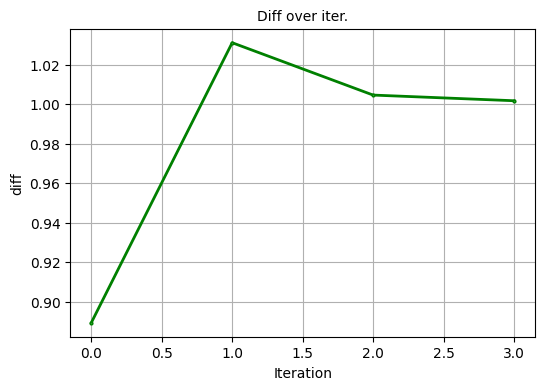

In [199]:
fig = plt.figure()
fig.set_figheight(4)
fig.set_figwidth(6)
ax = fig.add_subplot(111)
plot_x=np.array(x_f[0:5])
diff = plot_x-[0, 0, 0, 0]

plot_diff_list =[]
for i in range(1, len(diff)):
  plot_diff = np.linalg.norm(diff[i])/np.linalg.norm(diff[i-1])
  plot_diff_list.append(plot_diff)


ax.plot(list(range(0,len(plot_diff_list))), plot_diff_list, color='g', linestyle='solid', linewidth = 2,
            marker='o', markerfacecolor='tab:green', markersize=2)
ax.set_title('Diff over iter.', fontsize=10)
ax.set_ylabel('diff', fontsize=10)
ax.set_xlabel('Iteration', fontsize=10)
# ax.legend(fontsize=30)
ax.grid()
plt.show()